# Lab 3.3 — How does one model produce different continuations?

Open the trained character decoder from Lab 3.2. We'll run it once on `ROM`, save the last row of logits, and see how many choices we can make from that single row. Only in the last experiment will we feed a chosen character back into the model.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

from tiny_decoder import TinyDecoder
sys.path.insert(0, str(Path("../lm-internals").resolve()))
from lm_lab import load_ckpt, save_ckpt

torch.set_num_threads(1)
source = Path("checkpoints/lab32/tiny_decoder.npz")
saved = load_ckpt(source)
alphabet = saved["alphabet"].tolist()
index = {ch: i for i, ch in enumerate(alphabet)}
limit = int(saved["context_length"])
model = TinyDecoder(len(alphabet), limit, int(saved["width"]))
model.load_state_dict({k: torch.from_numpy(saved[k]) for k in model.state_dict()})
model.eval()

@torch.inference_mode()
def next_logits(prefix):
    ids = torch.tensor([[index[ch] for ch in prefix[-limit:]]])
    return model(ids)[0, -1]

def leaders(probs, count=3):
    values, ids = probs.topk(count)
    return [(alphabet[i], round(v.item(), 4)) for v, i in zip(values, ids)]

logits = next_logits("ROM")
base = logits.softmax(0)
print("After ROM:", leaders(base))

After ROM: [('E', 0.6191), ('I', 0.2238), (':', 0.0573)]


## 1. Stay at one position

**Greedy decoding** chooses the largest logit. **Sampling** draws a character with probability proportional to $\exp(z_i/T)$, where $z_i$ is its logit and $T$ is a positive temperature. Dividing by $T$ changes the gaps between logits. For example, the odds of E relative to I are $\exp((z_E-z_I)/T)$. Halving the temperature squares those odds.

Before running the cell, predict which bar will grow at $T=0.5$. Could another character overtake E at $T=2$? The three panels use the same four characters and vertical scale. The dots show frequencies from 1,000 independent draws per temperature; every draw starts after `ROM`.

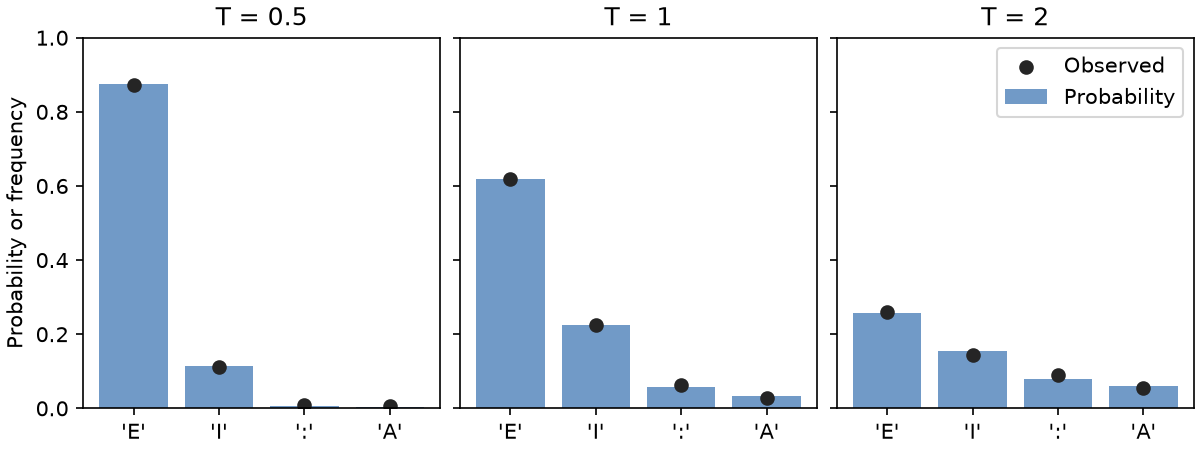

In [2]:
temps = [0.5, 1.0, 2.0]
rng = torch.Generator().manual_seed(33)
shown = base.topk(4).indices
counts, theoretical = [], []
fig, axes = plt.subplots(1, 3, figsize=(8, 3), sharey=True, layout="constrained")
for ax, temp in zip(axes, temps):
    probs = (logits / temp).softmax(0)
    draws = torch.multinomial(probs, 1000, replacement=True, generator=rng)
    freq = torch.bincount(draws, minlength=len(alphabet))
    counts.append(freq)
    theoretical.append(probs)
    assert probs.argmax() == base.argmax()
    ax.bar(range(4), probs[shown], color="#719ac7", label="Probability")
    ax.scatter(range(4), freq[shown] / 1000, color="#252525", label="Observed")
    ax.set_xticks(range(4), [repr(alphabet[i]) for i in shown])
    ax.set(title=f"T = {temp:g}", ylim=(0, 1))
axes[0].set_ylabel("Probability or frequency")
axes[-1].legend()
figure = Path("figures/lab33/temperature.png")
figure.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure, dpi=150)
plt.close(fig)
display(Image(filename=str(figure)))

## 2. Find the top-p cutoff by hand

At temperature 1, sort the characters from most to least probable. **Top-p sampling** keeps the shortest prefix of that list whose probabilities add up to at least p. Include the character that crosses the threshold. Predict where you would stop for 0.80 and 0.90 before running the cell.

To sample from the survivors, divide each probability by their total mass. If E originally had 0.619 and the survivors carry 0.843 together, what probability should E get now?

In [3]:
ordered, ids = base.sort(descending=True)
cumulative = ordered.double().cumsum(0)
for i in range(5):
    print(repr(alphabet[ids[i]]), f"p={ordered[i]:.5f}  running sum={cumulative[i]:.5f}")

def nucleus(probs, cutoff):
    if not 0 < cutoff <= 1:
        raise ValueError("cutoff must be in (0, 1]")
    values, order = probs.sort(descending=True)
    total = values.double().cumsum(0)
    size = int(torch.searchsorted(total, cutoff * total[-1])) + 1
    kept = order[:size]
    result = torch.zeros_like(probs)
    result[kept] = probs[kept] / probs[kept].sum()
    return result

for cutoff in (0.80, 0.90):
    filtered = nucleus(base, cutoff)
    torch.testing.assert_close(filtered.sum(), torch.tensor(1.))
    print(f"Top-p {cutoff:.2f} after renormalizing:", leaders(filtered, int(filtered.count_nonzero())))

'E' p=0.61914  running sum=0.61914
'I' p=0.22378  running sum=0.84292
':' p=0.05731  running sum=0.90023
'A' p=0.03424  running sum=0.93447
'O' p=0.01240  running sum=0.94687
Top-p 0.80 after renormalizing: [('E', 0.7345), ('I', 0.2655)]
Top-p 0.90 after renormalizing: [('E', 0.6878), ('I', 0.2486), (':', 0.0637)]


## 3. Follow the first fork

Start both paths at `ROM`. One takes the most probable character. The other samples at temperature 1 from the full distribution. As long as their prefixes match, the decoder gives them exactly the same logits. Stop at the first different choice. Predict which probabilities must agree immediately before that choice, then inspect the next model call for each branch.

In [4]:
prefix = "ROM"
rng = torch.Generator().manual_seed(33)
for step in range(1, 65):
    probs = next_logits(prefix).softmax(0)
    greedy = alphabet[probs.argmax()]
    sampled = alphabet[torch.multinomial(probs, 1, generator=rng).item()]
    if sampled != greedy:
        break
    prefix += greedy
else:
    raise RuntimeError("No fork observed in this seeded run")

branches = [prefix + greedy, prefix + sampled]
after = torch.stack([next_logits(branch).softmax(0) for branch in branches])
print("Shared prefix:", repr(prefix), "| shared distribution:", leaders(probs))
for label, branch, distribution in zip(("Greedy", "Sampled"), branches, after):
    print(label, repr(branch), "→ next-character probabilities:", leaders(distribution))
print("First fork at generated character", step)

Shared prefix: 'ROM' | shared distribution: [('E', 0.6191), ('I', 0.2238), (':', 0.0573)]
Greedy 'ROME' → next-character probabilities: [('N', 0.5287), ('R', 0.2294), ('S', 0.0669)]
Sampled 'ROMI' → next-character probabilities: [('N', 0.6495), ('L', 0.0571), ('O', 0.0555)]
First fork at generated character 1


What changed at the fork while the model still had the same prefix? One step later, which part of the calculation now receives a different input? Use the printed characters and probabilities to explain the distinction in your own words.

### Save the experiment

The Lab 3.2 checkpoint supplies the weights. Save the distributions, sample counts and fork here so you can revisit the figure and both branches.

In [5]:
record = save_ckpt(Path("checkpoints/lab33"), "decoding_trace",
                   metrics={"draws_per_temperature": 1000, "fork_step": step},
                   alphabet=np.array(alphabet), temperatures=np.array(temps),
                   probabilities=torch.stack(theoretical).numpy(),
                   counts=torch.stack(counts).numpy(), branches=np.array(branches),
                   before=probs.numpy(), after=after.numpy())
trace = load_ckpt(record)
assert (trace["counts"].sum(axis=1) == 1000).all()
np.testing.assert_allclose(trace["after"].sum(axis=1), 1, atol=1e-6)
print("Saved", record)

Saved checkpoints/lab33/decoding_trace.npz
